<a id="chapter-16"></a>

# Chapter 16 · Trust Regions - PPO, TRPO, ACKTR, and SAC / 信赖域方法

[← 学习索引](../README.md) · [项目主页](../../README.md) · [跳到本章扩展](#extension)

> 学习方式：按顺序读到代码单元，先预测输出再运行。正文只保留理解主线；非必要的证明、变体与工程细节放在[扩展](#extension)。

**学完本章，你应该能：**

- 理解策略更新不能迈太大步
- 掌握 PPO clipped objective
- 区分 TRPO、ACKTR 与 SAC 的核心想法

**开始前最好已经会：**

- 掌握 actor-critic 与 advantage
- 理解概率比值
- 知道 KL divergence 的直觉


## 原书覆盖地图

| 原书主题 | 本 notebook 对应位置 | 深度 |
|---|---|---|
| Environments / A2C baseline | 公平基线与评估 | 详细 |
| PPO | ratio、clip、epoch 流程 | 详细 |
| TRPO | KL 约束、共轭梯度、线搜索 | 详细 |
| ACKTR | 自然梯度与 K-FAC | 结构理解 |
| SAC | 最大熵、双 Q、温度 | 详细 |
| Overall results | 同协议比较 | 详细 |

“详细”表示正文包含推导或完整数据流；“源码路线”表示正文解释职责并链接真实实现；次要变体保留在扩展区。这样可以明确看到本章没有把原书哪个主题悄悄跳过。


## 0. 先想一个问题

策略梯度的一次更新如果太大，新策略会突然忘掉旧行为。怎样在提升回报的同时限制策略变化？

> 不必立刻回答。读完本章后再回到这里，尝试用两三句话作答。


## 1. 心智模型：先知道信息怎样流动

旧策略收集的数据只适合有限幅度的新策略更新。TRPO 施加 KL 约束；PPO 用 clipping 近似；ACKTR 用曲率信息；SAC 最大化回报与熵。

学习时始终追问三件事：**当前已知什么？要估计什么？哪个量会被更新？** 这比先背算法名称更重要。


## 2. 符号表：先统一语言

| 符号/名称 | 含义 | 阅读时怎么想 |
|---|---|---|
| $\pi_{old}$ | 采集当前 batch 的旧策略 | 一个 PPO update 周期内固定 |
| $r_t(\theta)$ | 新旧动作概率比 | 衡量该动作概率变化 |
| $\epsilon$ | PPO clip 范围 | 常见如 0.1 或 0.2 |
| KL | 新旧策略差异 | 监控更新幅度 |
| $\alpha$ | SAC entropy 温度 | 探索与回报权衡 |

第一次阅读只需认识这些符号；看到公式时再回来查，不要求一次背完。


## 3. 分步推导：公式不是凭空出现的


### 1. 为什么出现概率比

数据来自旧策略，但目标想评估新策略。importance sampling 给出

$$\mathbb E_{a\sim\pi_\theta}[f(a)]
=\mathbb E_{a\sim\pi_{old}}\left[\frac{\pi_\theta(a|s)}{\pi_{old}(a|s)}f(a)\right]$$

令 $r_t(\theta)=\exp(\log\pi_\theta-\log\pi_{old})$，unclipped surrogate 为 $r_t\hat A_t$。

### 2. PPO 为什么取两个项的 minimum

$$L^{clip}=\mathbb E[\min(r_t\hat A_t,
\operatorname{clip}(r_t,1-\epsilon,1+\epsilon)\hat A_t)]$$

- $\hat A>0$：不再奖励把好动作概率提高到 $1+\epsilon$ 以上。
- $\hat A<0$：不再奖励把坏动作概率降低到 $1-\epsilon$ 以下。

`min` 与 advantage 符号共同形成分段行为；不能简单理解为“把 ratio 永远截断”。

### 3. TRPO/ACKTR/SAC 放在同一章的原因

TRPO 显式近似求解 KL 约束优化；ACKTR 用 K-FAC 近似自然梯度曲率；SAC 则是 off-policy 最大熵 actor-critic，目标包含 $+\alpha H(\pi)$。它们都关注稳定更新，但数据分布和优化形式不同。


## 4. 手算一个最小例子


设 $\epsilon=0.2$。

- $A=+1,r=1.5$：unclipped=1.5，clipped=1.2，取 1.2。
- $A=-1,r=0.5$：unclipped=-0.5，clipped=-0.8，取 -0.8。
- $A=+1,r=0.7$：取 0.7；PPO 不阻止“朝错误方向”的变化，而是让梯度继续纠正它。

这三个数值例子比只背公式更能理解 clipping。


> 手算的目的不是练算术，而是给公式建立可检查的直觉。代码输出与手算矛盾时，先停下来找原因。


## 5. 本章公式卡


### PPO 与 SAC

$r_t(\theta)=\pi_\theta(a_t|s_t)/\pi_{old}(a_t|s_t)$。

$$L^{clip}=\mathbb E\left[\min(r_t\hat A_t,\operatorname{clip}(r_t,1-\epsilon,1+\epsilon)\hat A_t)\right]$$

SAC 的最大熵目标：
$$J(\pi)=\mathbb E\sum_t\gamma^t\left(R_{t+1}+\alpha\mathcal H(\pi(\cdot|S_t))\right)$$

PPO 不是严格 KL 约束；仍应监控 approximate KL 与 clip fraction。


这张卡用于复习，不替代上一节的推导。


## 6. 公式 ↔ 代码逐项对照

| 数学对象/步骤 | 代码对应 | 作用与形状提示 |
|---|---|---|
| $\log\pi_{old}$ | `old_logp` | rollout 时缓存并固定 |
| $\log\pi_\theta$ | `new_logp` | 当前网络重新计算 |
| $r_t$ | `(new_logp - old_logp).exp()` | 用 log 差避免直接除小概率 |
| $r_t\hat A$ | `unclipped` | 原始 surrogate |
| clip 项 | `ratio.clamp(1-eps, 1+eps) * advantage` | 保守边界 |
| 最大化 $L^{clip}$ | `loss = -minimum(...).mean()` | 优化器执行最小化 |

**从公式过渡到代码时：**用正负 advantage 观察 PPO clipping：clip 的作用方向取决于 advantage 符号。


## 7. 动手实验

运行前先做三件事：

1. 根据手算例子预测关键输出的方向或数量级；
2. 找到上一张表中的每个代码变量；
3. 运行后只改一个变量，观察结果是否符合公式。


In [1]:
import torch

old_logp = torch.tensor([-0.7, -0.7, -0.7, -0.7])
new_logp = torch.tensor([-0.6, -0.2, -1.3, -0.8], requires_grad=True)
advantage = torch.tensor([1.0, 1.0, -1.0, -1.0])
ratio = (new_logp - old_logp).exp()
epsilon = 0.2
unclipped = ratio * advantage
clipped = ratio.clamp(1 - epsilon, 1 + epsilon) * advantage
loss = -torch.minimum(unclipped, clipped).mean()
loss.backward()
print("ratio:", ratio.detach().round(decimals=3))
print("PPO loss:", loss.item(), "approx KL:", (old_logp - new_logp).mean().item())


ratio: tensor([1.1050, 1.6490, 0.5490, 0.9050])
PPO loss: -0.15008342266082764 approx KL: 0.025000005960464478


### 怎样读运行结果

逐项比较 `unclipped` 与 `clipped`，不要只看平均 loss。approximate KL 只是样本估计；实践中还应记录 clip fraction，并在 KL 过大时提前停止 epoch。

如果结果不符合描述，先检查随机种子、终止 mask、数组 shape 和依赖版本，而不是马上调超参数。


## 8. 完整算法：把前面的零件装起来


```text
PPO：冻结 rollout 时的 old_log_prob 和 old_value
计算 returns / advantages
for epoch in 1..K:
  shuffle 成 minibatches
  new_log_prob, value, entropy = model(batch)
  ratio = exp(new-old)
  policy = -mean(min(ratio*A, clip(ratio)*A))
  value_loss = regression(value, return)（可 value clip）
  更新；若 approximate KL 超阈值则提前结束 epoch

TRPO：用 Fisher-vector product + conjugate gradient 求受 KL 约束方向，再 line search。
SAC：从 replay 更新 twin Q、随机 actor 和 temperature α，并 soft-update targets。
```


## 9. 第二个验证实验

第一个实验负责建立直觉；下面这个实验专门验证一个容易写错的性质。它仍然保持轻量，目的是让你能用断言判断实现是否符合公式。


In [2]:
import numpy as np

eps = 0.2
cases = [(1.5, 1.0), (0.5, -1.0), (0.7, 1.0), (1.3, -1.0)]
for ratio, adv in cases:
    raw = ratio * adv
    clipped = np.clip(ratio, 1-eps, 1+eps) * adv
    surrogate = min(raw, clipped)
    print({"ratio": ratio, "A": adv, "raw": raw,
           "clip_term": clipped, "used": surrogate})


{'ratio': 1.5, 'A': 1.0, 'raw': 1.5, 'clip_term': 1.2, 'used': 1.2}
{'ratio': 0.5, 'A': -1.0, 'raw': -0.5, 'clip_term': -0.8, 'used': -0.8}
{'ratio': 0.7, 'A': 1.0, 'raw': 0.7, 'clip_term': 0.8, 'used': 0.7}
{'ratio': 1.3, 'A': -1.0, 'raw': -1.3, 'clip_term': -1.2, 'used': -1.3}


## 10. 项目源码精读路线

| 文件 | 重点类/函数 | 阅读目的 |
|---|---|---|
| [`01_train_a2c.py`](../../Chapter16/01_train_a2c.py) | 共同 baseline | 环境/评估协议 |
| [`03_train_ppo.py`](../../Chapter16/03_train_ppo.py) | PPO epoch/minibatch | old log-prob 与 clip loss |
| [`trpo.py`](../../Chapter16/lib/trpo.py) | 共轭梯度、线搜索 | TRPO 数值核心 |
| [`04_train_trpo.py`](../../Chapter16/04_train_trpo.py) | TRPO trainer | KL 约束如何接入 rollout |
| [`kfac.py`](../../Chapter16/lib/kfac.py) | K-FAC optimizer | ACKTR 曲率近似 |
| [`06_train_sac.py`](../../Chapter16/06_train_sac.py) | SAC | off-policy replay、双 critic、entropy |

<details>
<summary>为什么按这个顺序读</summary>

PPO 精读时确认 `old_log_prob` 来自采样时策略并跨多个 epoch 固定；若每轮重算，ratio 会退化。TRPO 的 `conjugate_gradients` 不显式构造巨大 Fisher 矩阵，而只需要矩阵-向量积；line search 检查实际 KL 与 surrogate 改善。SAC 与前面三者不同：它是 off-policy，通常用 twin Q 的较小值抑制过估计，并可能自动优化 $\alpha$ 使 entropy 接近目标。

</details>

notebook 的实验负责隔离原理，仓库脚本负责完整环境、日志和训练。阅读时拿着第 6 节对照表寻找同一数学对象；变量名可以不同，数据语义不能不同。


## 11. 训练曲线、调参与失败复盘

**本章主诊断指标：**PPO 更新中的回报代理指标与 KL

下面的曲线来自可重复运行的微型训练，不是手工填写的数据。它用于学习“该看什么、怎样判断”；原书规模的训练应使用上一节链接的项目脚本，并同时保存配置、随机种子、环境步数和 wall-clock。

> 曲线阅读顺序：先看任务指标，再看优化指标，最后看资源指标。单次最好成绩不能代替多随机种子均值与波动。


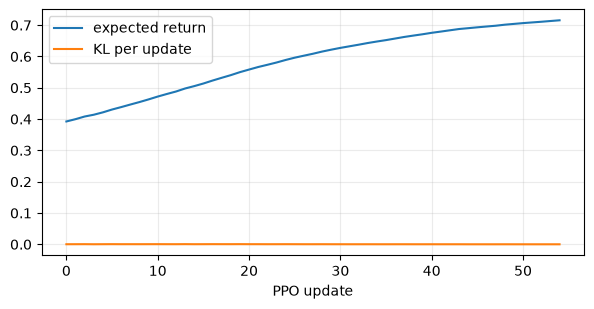

final expected return / max KL: 0.716 0.0005


In [3]:
import numpy as np
import matplotlib.pyplot as plt

def plot_curve(series, title, ylabel, *, window=1):
    # Plot raw measurements and an optional moving average.
    values = np.asarray(series, dtype=float)
    x = np.arange(1, len(values) + 1)
    plt.figure(figsize=(7, 3.2))
    plt.plot(x, values, alpha=0.35, label="raw")
    if window > 1 and len(values) >= window:
        smooth = np.convolve(values, np.ones(window) / window, mode="valid")
        plt.plot(x[window - 1:], smooth, linewidth=2, label=f"MA({window})")
    plt.title(title)
    plt.xlabel("iteration / episode")
    plt.ylabel(ylabel)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.show()
    plt.close()


rng = np.random.default_rng(16)
theta, returns, kls = -0.8, [], []
for update in range(55):
    old_p = 1 / (1 + np.exp(-theta))
    actions = (rng.random(256) < old_p).astype(float)
    rewards = np.where(actions == 1, rng.normal(.8, .3, 256), rng.normal(.2, .3, 256))
    advantages = rewards - rewards.mean()
    old_prob = np.where(actions == 1, old_p, 1 - old_p)
    for _ in range(5):
        p = 1 / (1 + np.exp(-theta))
        prob = np.where(actions == 1, p, 1 - p)
        ratio = prob / old_prob
        active = ((advantages >= 0) & (ratio < 1.2)) | ((advantages < 0) & (ratio > .8))
        grad_logp = actions - p
        theta += .08 * np.mean(active * ratio * advantages * grad_logp)
    new_p = 1 / (1 + np.exp(-theta))
    kl = old_p*np.log((old_p+1e-9)/(new_p+1e-9)) + (1-old_p)*np.log((1-old_p+1e-9)/(1-new_p+1e-9))
    returns.append(.2 + .6 * new_p); kls.append(kl)

plt.figure(figsize=(7, 3.2)); plt.plot(returns, label="expected return"); plt.plot(kls, label="KL per update")
plt.xlabel("PPO update"); plt.grid(alpha=.25); plt.legend(); plt.show(); plt.close()
print("final expected return / max KL:", round(returns[-1], 3), round(max(kls), 4))


### 曲线怎么读

期望回报应上升，而每次更新 KL 保持较小。若 surrogate objective 变好但 KL 突增、回报坍缩，说明 epoch、学习率或 clip 过于激进。

### 调参过程：一次只改变一个因素

- 固定 rollout length，先调 actor learning rate 使 KL 落在稳定范围。
- 再调 PPO epochs/minibatch；epoch 增加会提高样本复用也会推高 KL。
- 最后调 clip、GAE $\lambda$、entropy，并同时报告 explained variance。

### 失败案例复盘

- 每个 minibatch 重算 old log-prob，ratio 永远接近 1。
- advantage 未标准化且尺度剧烈变化。
- 只监控 clipped loss，不监控 KL、entropy 与实际回报。

遇到失败时先保存配置和原始曲线，复现后再修；不要一边改环境、一边改网络、一边改学习率，否则无法知道修复来自哪里。


## 12. 实用技巧与常见坑

- 缓存 old log-prob，多个 epoch 内不要重新计算成当前策略。
- advantage 标准化与 value clipping 会显著影响 PPO。
- clip loss 正常不代表更新安全，仍要设置 target KL 或早停。

这些不是附属知识：RL 结果方差大，很多“算法没学会”其实是终止语义、shape、数据泄漏或评估方式错误。


## 13. 动手练习

逐项打印 unclipped 和 clipped surrogate；找出哪些样本真正触发保守边界。

<details>
<summary>完成标准（做完再展开）</summary>

不只给出结果；还应说明改了哪个变量、对应哪条公式、变化是否符合预期，并写出至少一个边界情况。若能用 `assert` 固化结论更好。
</details>


## 14. 练习参考答案

<details>
<summary>完成练习后再展开</summary>

打印四个样本的 `raw` 与 `clip_term`，只有当过度改变会让 surrogate 更乐观时，`min` 才选择保守项。正 advantage 且 ratio>1.2、负 advantage 且 ratio<0.8 是典型触发；朝错误方向的变化仍保留梯度纠正。

</details>


## 15. 合上 notebook 后，脑中应留下什么

- PPO ratio 来自 importance sampling。
- clipping 的作用必须结合 advantage 正负理解。
- old log-prob 在同一轮多 epoch 更新中保持固定。
- PPO、TRPO、ACKTR、SAC 都关注稳定性，但不是同一种算法。

回到开头的那个问题。现在请不用公式，向一个没学过本章的人解释答案；能讲清楚，才算真正理解。


## 16. 两分钟自测

**问题：**为什么 PPO 存 log-prob 而不是概率？clipping 是否保证 KL 一定很小？

<details>
<summary>展开答案</summary>

log 概率数值更稳定，ratio 可由 log 差取 exp 得到。clipping 只限制采样动作上的 surrogate 激励，并不严格保证整体 KL，因此仍要监控 KL。
</details>


## 17. 与前后章节连接

第 17 章完全绕开反向传播；第 18 章比较这些策略方法与价值方法在探索任务上的表现。

学习强化学习最怕把算法记成孤岛。每章结束时，都应能说明本章复用了前面的什么，又为后面准备了什么。


<a id="extension"></a>

## 扩展：主线学完后再深挖

TRPO 通过共轭梯度近似自然梯度；ACKTR 用 K-FAC 近似 Fisher；SAC 是 off-policy 并可自动调温度 $\alpha$。

扩展内容用于建立知识地图，不要求第一次学习就掌握。先确保能完成上面的两分钟自测，再决定是否继续。

[↑ 回到开头](#chapter-16) · [← 学习索引](../README.md)
